In [ ]:
pip install tensorflow

In [ ]:
!pip install -q tensorflow-datasets

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, datasets
import matplotlib.pyplot as plt

In [ ]:
#загружаю данные датасета cifar-10(встроен в keras)
#x_train - картинки, y_train - правильные ответы(цифры 0 - 9)

(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step


Размер тренировочных данных: (50000, 32, 32, 3)
Размер тестовых данных(10000, 32, 32, 3)
кол-во классов - 10


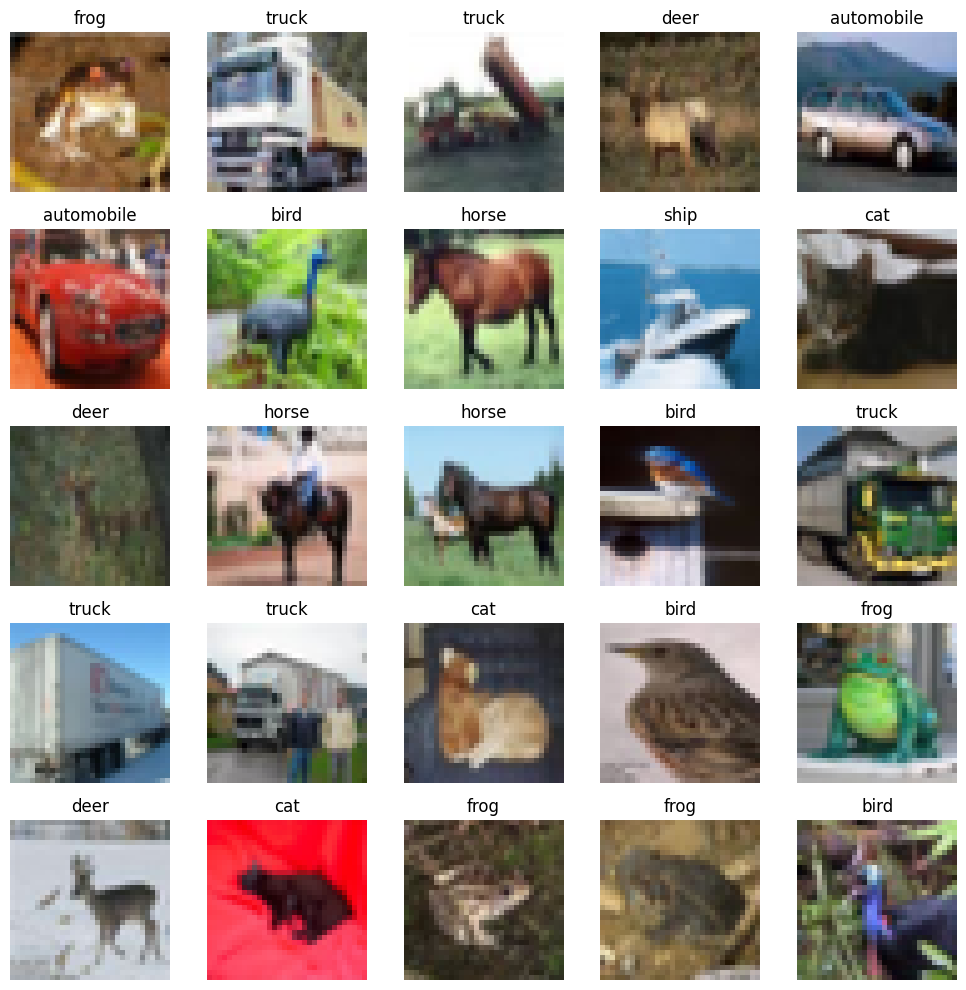

In [ ]:
#датасет выглядит вот так
print(f'Размер тренировочных данных: {x_train.shape}')
print(f'Размер тестовых данных{x_test.shape}')
print('кол-во классов - 10')

#названия классов
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog',
               'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(25):
  plt.subplot(5, 5, i + 1)
  plt.imshow(x_train[i])
  plt.title(class_names[y_train[i][0]])
  plt.axis('off')
plt.tight_layout()
plt.show()

_________________________________________________________________

**крч в чем разница между сегментацией и классификацией**

 **классификация :**

**1. conv2d - первый слой который берет каждый пиксель по очереди и смотрит изучает нюхает и тд, так же запоминает что у него есть и где это у него есть**

**2. пулинг - сжиматель, берет и сжимает картинку, на основе того что нашел конв2д оставляет самое нужное или же суть фотки картинки, и сжимает ее, картинка меньше значит пк считывает ее быстрее**

**3. flatten - слой настоящая линейка, собирает все признаки которые сначала выбрали потом сжали по очереди в одну линию**
**4. dense - слой который принимает решение к какому классу относить то или иное изображение собранное из всех пикселей**

**ИТОГ - на выходе одно число или вектор состоящий из 10 чисел(вероятности классов)**

_________________________________________________________________

**Сегментация это как раз про условия изображения и того что там находится, мы делаем из изображения раскраску типо кот - красный дорога - синий**

**в классификации после слоев flatten dense мы забыли где находится тт или иной объект, мы не знаем где верх где низ и как собрать пазл из пикселей**

**поэтому тут только два этапа энкодер и декодер, первый из которых сжимает картинку до маленького квадратика на этом этапе сеть понимает КОНТЕКСТ изображения типо что на фото изображено**

**после декодер который постепенно растягивает квадратик **

**на выходе получаем не одно число а целую карту маску размером с исходную картинку где у каждого пикселя есть класс(цвет)**

_________________________________________________________________

In [ ]:
#нормализация данных
#делим на 255, чтобы числа были от 0 до 1 так будет оегче обучаться

x_train, x_test = x_train / 255.0, x_test / 255.0

In [ ]:
 #далее пошагово строим архитектуру сети

model_classification = models.Sequential([
    #1 ищем простые линии
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)), #тут сжимаем картинку

    #2 ищем более сложные формы
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    #3 ищем сложные объекты
    layers.Conv2D(64, (3, 3), activation='relu'),

    #4 превращаем картинку в плоский список чисел
    layers.Flatten(),

    # 5 dense слои
    layers.Dense(64, activation='relu'),
    # Выход: 10 нейронов (по одному на каждый класс CIFAR-10)
    # softmax превращает числа в вероятности (сумма = 100%)
    layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


крч че происходит сверху


> **layers.Conv2D(32, (3,3), activation='relu', input_shape=(32, 32, 3))**

32 - фильтры, каждый из которых ищет определенный признак(вертикальная линия, горизонтальная линия, точка и тд)

3, 3 - размер лупы(окна свертки), золотой стандарт, слишком мал чтобы ловить локальные детали, но достотаточен чтобы покрыть площадь

activation='relu' - функция активации ReLU (Rectified Linear Unit). Формула:
f(x)=max(0,x). Все отрицательные числа она превращает в 0, положительные оставляет как есть.

input_shape=(32, 32, 3) - размер картинки на входе 32 в высоту и 32 в ширину, а 3 канала ргб(красный зеленый синий)



> **layers.MaxPooling2D((2, 2))**

2, 2 - берет квадрат 2 на 2 смотрит на 4 числа и оставляет максимальное а остальные выкидывает



> **layers.Conv2D(64, (3, 3), activation='relu')**

64 фильтра, типо по логике теперь нам надо собирать из простых вещей какую то или какие то геометрию/и поэтому удваиваем значение (значение принимает из степеней 2)

размерность на выходе картинка сжалась на 2 пикселя с каждой стороны размер стал 13,13,64









In [ ]:
# компиляция
model_classification.compile(optimizer='adam',
                             loss='sparse_categorical_crossentropy',
                             metrics=['accuracy'])

In [ ]:
# обучение
print('___ОБучЕНие модели классификации___')
model_classification.fit(x_train, y_train, epochs=10, validation_data=(x_test,y_test))

___ОБучЕНие модели классификации___
Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 76s 47ms/step - accuracy: 0.4322 - loss: 1.5472 - val_accuracy: 0.5408 - val_loss: 1.2812
Epoch 2/10
1546/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5714 - loss: 1.2052

KeyboardInterrupt: 

In [ ]:
import numpy as np

# Получаем предсказания на тестовых данных
predictions = model_classification.predict(x_test)

# predictions.shape = (10000, 10) - для каждой картинки 10 вероятностей
# argmax находит индекс класса с максимальной вероятностью
predicted_classes = np.argmax(predictions, axis=1)

# Визуализируем первые 25 картинок с предсказаниями
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_test[i])

    true_label = class_names[y_test[i][0]]
    pred_label = class_names[predicted_classes[i]]

    # Если предсказание верное - зелёный текст, если нет - красный
    color = 'green' if predicted_classes[i] == y_test[i][0] else 'red'

    plt.title(f'{pred_label}\n(факт: {true_label})', color=color, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
model_classification.save('classification_model.h5')

теперь СЕГМЕНТАЦИЯ

из приколюх, мне нужно взять 'упрощенный датасет' честно я задалбался его искать а делать самому лень

In [ ]:
!pip install -q "protobuf>=6.31.1,<7.0.0" tensorflow-datasets importlib_resources

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 6.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 6.33.6 which is incompatible.


`import tensorflow_datasets as tfds` - чтобы установить другой датасет предусмотренный в tensorflow

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
dataset = tfds.load('oxford_iiit_pet', split='train[:20]', as_supervised=False)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.G73Y1T_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.G73Y1T_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
x_seg_train = []
y_seg_train = []

for example in dataset:
    image = example['image']
    mask = example['segmentation_mask']

    img = tf.cast(image, tf.float32)
    img = tf.image.resize(img, [128, 128]) / 255.0

    msk = tf.cast(mask, tf.int32)
    msk = tf.image.resize(msk, [128, 128], method='nearest')

    msk = msk - 1  # классы 1,2,3 -> 0,1,2

    if len(msk.shape) == 2:
        msk = tf.expand_dims(msk, axis=-1)

    x_seg_train.append(img.numpy())
    y_seg_train.append(msk.numpy())

x_seg_train = np.array(x_seg_train, dtype='float32')
y_seg_train = np.array(y_seg_train, dtype='int32')

print(f"Размер картинок (X): {x_seg_train.shape}")  # (20, 128, 128, 3)
print(f"Размер масок (Y): {y_seg_train.shape}")     # (20, 128, 128, 1)

Размер картинок (X): (20, 128, 128, 3)
Размер масок (Y): (20, 128, 128, 1)


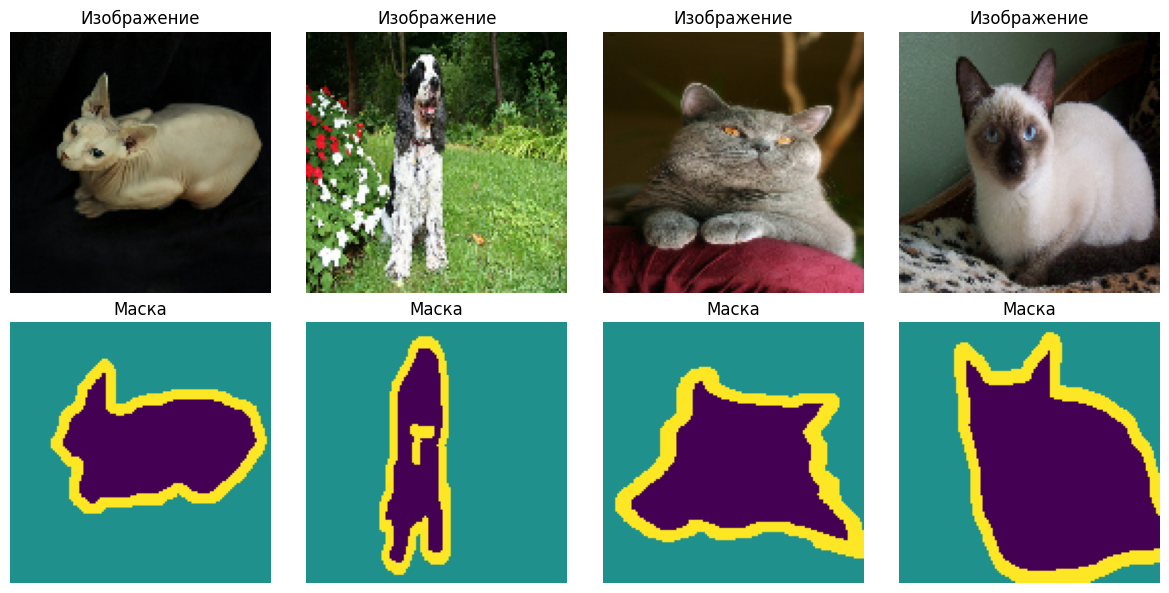

In [ ]:
# Посмотрим на несколько пар "картинка + маска"
n = 4
plt.figure(figsize=(12, 6))
for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(x_seg_train[i])
    plt.title("Изображение")
    plt.axis('off')

    plt.subplot(2, n, n + i + 1)
    plt.imshow(y_seg_train[i, :, :, 0], cmap='viridis')  # классы 0,1,2
    plt.title("Маска")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
x_train, x_val = x_seg_train[:16], x_seg_train[16:]
y_train, y_val = y_seg_train[:16], y_seg_train[16:]

In [ ]:
from tensorflow.keras import layers, models

num_classes = 3  # 0, 1, 2

def build_segmentation_model(input_shape=(128, 128, 3), num_classes=3):
    inputs = layers.Input(shape=input_shape)

    #еncoder
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2)(x)          # 128 -> 64

    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
    x = layers.MaxPooling2D(2)(x)          # 64 -> 32

    x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
    x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)  # "бутылочное горлышко"

    #decoder
    x = layers.Conv2DTranspose(64, 3, strides=2, activation='relu', padding='same')(x)  # 32 -> 64
    x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)

    x = layers.Conv2DTranspose(32, 3, strides=2, activation='relu', padding='same')(x)  # 64 -> 128
    x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)

    #Выходной слой
    outputs = layers.Conv2D(num_classes, 1, activation='softmax', padding='same')(x)

    model = models.Model(inputs, outputs)
    return model

seg_model = build_segmentation_model(num_classes=num_classes)
seg_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 64, 64, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 128, 128, 32)   │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 128, 128, 3)    │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 425,539 (1.62 MB)

 Trainable params: 425,539 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
seg_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',  # маски - целые числа классов, не one-hot
    metrics=['accuracy']
)

history = seg_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    batch_size=4,
    epochs=20
)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.6850 - loss: 1.0885 - val_accuracy: 0.5375 - val_loss: 1.0396
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.5849 - loss: 0.9418 - val_accuracy: 0.7030 - val_loss: 0.8786
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.5796 - loss: 0.8850 - val_accuracy: 0.4918 - val_loss: 0.9125
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 769ms/step - accuracy: 0.5925 - loss: 0.8262 - val_accuracy: 0.4916 - val_loss: 0.9567
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 782ms/step - accuracy: 0.5928 - loss: 0.7821 - val_accuracy: 0.5356 - val_loss: 0.9589
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 884ms/step - accuracy: 0.6680 - loss: 0.7249 - val_accuracy: 0.6205 - val_loss: 0.9269
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 771ms/step - accuracy: 0.7233 - loss: 0.6815 - val_accuracy: 0.5759 - val_loss: 0.9760
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 770ms/step - accuracy: 0.7241 - loss: 0.6677 - val_accuracy: 0.5720 - val_loss: 0.9644


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 361ms/step


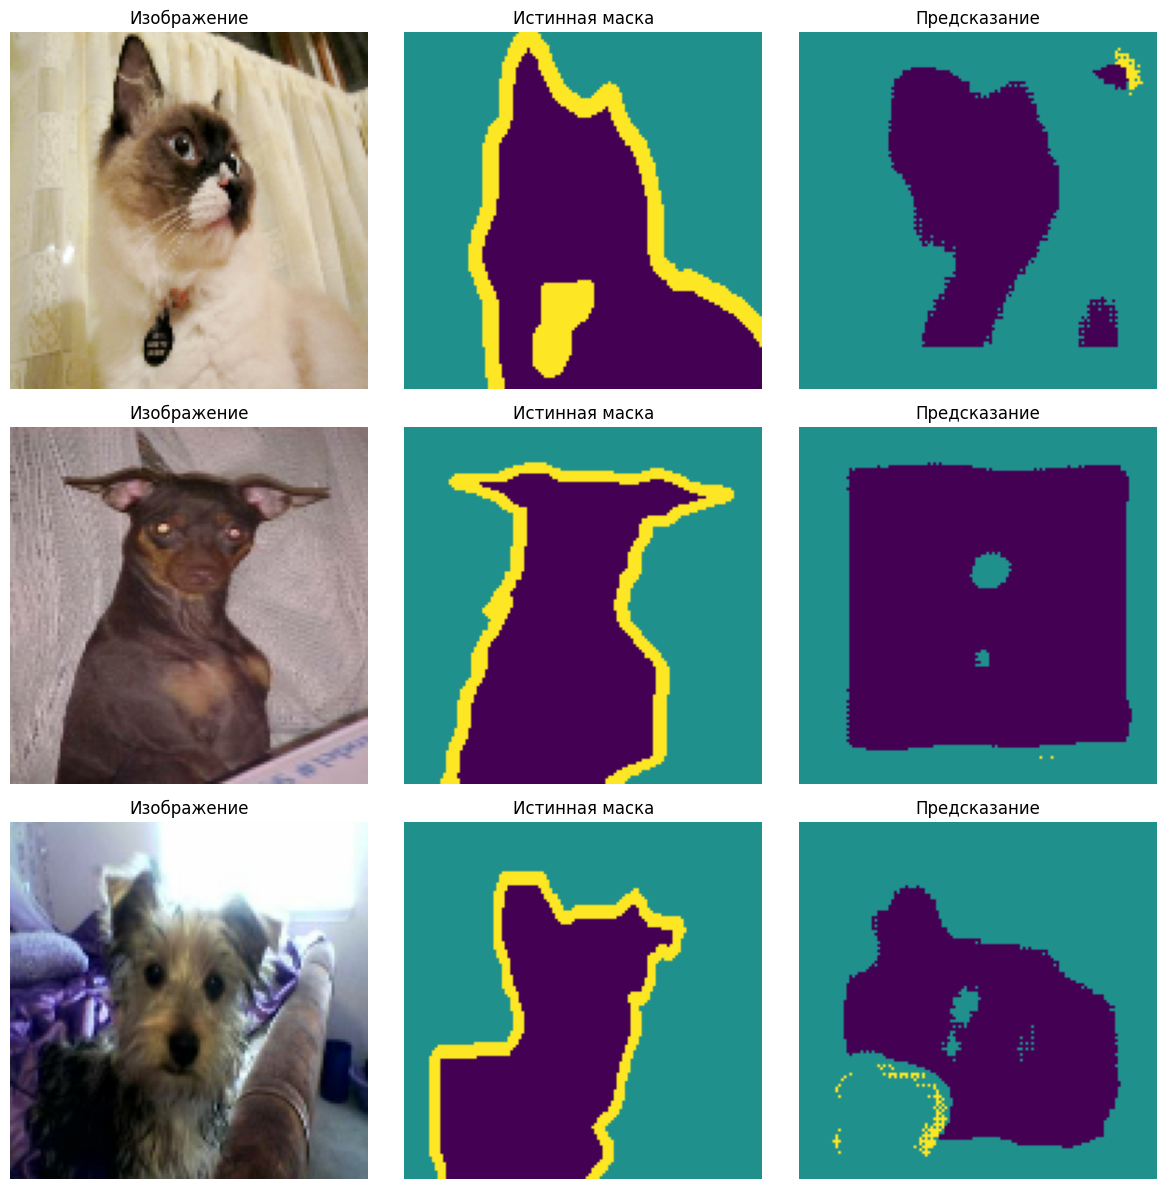

In [ ]:
pred = seg_model.predict(x_val)
pred_mask = np.argmax(pred, axis=-1)  # (N, 128, 128) - класс с макс. вероятностью

n = min(3, len(x_val))
plt.figure(figsize=(12, 4 * n))
for i in range(n):
    plt.subplot(n, 3, i * 3 + 1)
    plt.imshow(x_val[i])
    plt.title("Изображение")
    plt.axis('off')

    plt.subplot(n, 3, i * 3 + 2)
    plt.imshow(y_val[i, :, :, 0], cmap='viridis')
    plt.title("Истинная маска")
    plt.axis('off')

    plt.subplot(n, 3, i * 3 + 3)
    plt.imshow(pred_mask[i], cmap='viridis')
    plt.title("Предсказание")
    plt.axis('off')

plt.tight_layout()
plt.show()

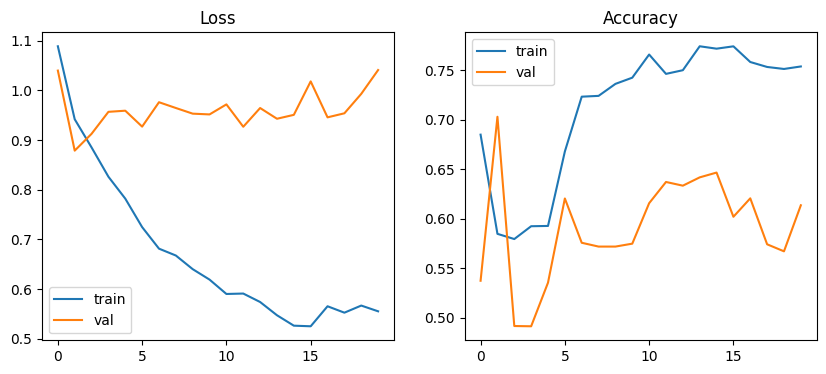

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title('Accuracy')
plt.legend()

plt.show()